# 03. Exploratory Data Analysis and Data-Quality Audit

**Input:** `data/processed/oulad_master_day28.csv` (one row per eligible student-presentation, features from days before 28).
**Purpose:** understand what the master table can and cannot support before any modelling.

Reading guide. Each key result is followed by three points: **observed**, **why it matters**, **action**.
With about 27,000 rows nearly every test is "significant", so the interpretation rests on **effect sizes** (Spearman rho, AUC, Cramer's V, odds ratios), not p-values.
All results are associations at day 28, not causal effects.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint

RANDOM_STATE = 42
CUTOFF_DAY = 28
RAW, PROC, OUT = Path("../data/raw"), Path("../data/processed"), Path("../outputs")
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
KEY = ["code_module", "code_presentation", "id_student"]

# Chart style: fixed categorical slots (blue = not at risk, orange = at risk), recessive grid, no top/right spines.
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
C_OK, C_RISK = "#2a78d6", "#eb6834"
SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 9, "figure.dpi": 110,
})
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

def savefig(fig, name):
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")

# ---- effect-size helpers -------------------------------------------------
def cramers_v(ct):
    # bias-corrected Cramer's V
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum(); r, k = ct.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2 / max(1e-12, min(kc - 1, rc - 1))))

def auc_pos(x, y):
    # probability that a random at-risk student has a HIGHER value than a random not-at-risk student (ties count half)
    d = pd.DataFrame({"x": x, "y": y}).dropna()
    a, b = d.loc[d.y == 1, "x"], d.loc[d.y == 0, "x"]
    return float(stats.mannwhitneyu(a, b).statistic / (len(a) * len(b)))

def odds_ratio(a, b, c, d):
    # 2x2: exposed with outcome a, exposed without b, unexposed with outcome c, unexposed without d (Woolf CI)
    orr = (a * d) / (b * c); se = np.sqrt(1 / a + 1 / b + 1 / c + 1 / d)
    return orr, orr * np.exp(-1.96 * se), orr * np.exp(1.96 * se)

def rate_table(df, col, order=None):
    g = df.groupby(col, observed=True).target_at_risk.agg(n="size", at_risk="sum")
    g["rate"] = g.at_risk / g.n
    g["lo"], g["hi"] = proportion_confint(g.at_risk, g.n, method="wilson")
    return g.reindex(order) if order is not None else g

master = pd.read_csv(PROC / "oulad_master_day28.csv")
print("master:", master.shape, "| overall at-risk rate:", round(master.target_at_risk.mean(), 3))

master: (27553, 46) | overall at-risk rate: 0.442


## 1. Data-quality audit

### 1.1 Structure and keys

In [2]:
assert not master.duplicated(KEY).any()
print(f"rows {len(master):,} | columns {master.shape[1]} | distinct students {master.id_student.nunique():,} | duplicate keys 0")
print(f"students appearing in more than one presentation: {int((master.groupby('id_student').size() > 1).sum()):,}")
master.dtypes.value_counts().to_frame("n columns")

rows 27,553 | columns 46 | distinct students 24,849 | duplicate keys 0
students appearing in more than one presentation: 2,583


,n columns
int64,31
object,10
float64,5


### 1.2 Missingness: how much, and is it random?

In [3]:
miss = master.isna().mean().mul(100)
miss = miss[miss > 0].sort_values(ascending=False).to_frame("missing_%")
miss["n"] = master[miss.index].isna().sum()
display(miss)

pat = master.assign(imd_na=master.imd_band.isna(), score_na=master.mean_score_early.isna(),
                    rate_na=master.submit_rate_early.isna(), click_na=master.first_click_day.isna())
by_mod = pat.groupby("code_module")[["imd_na", "score_na", "rate_na", "click_na"]].mean().mul(100).round(1)
by_mod.columns = ["imd_band missing %", "mean_score_early missing %", "submit_rate_early missing %", "first_click_day missing %"]
display(by_mod)

# Is missing IMD informative for the outcome?
t = rate_table(pat, "imd_na")
display(t.rename(index={False: "IMD recorded", True: "IMD missing"}))

,missing_%,n
mean_score_early,28.204,7771
submit_rate_early,18.114,4991
imd_order,3.735,1029
imd_band,3.735,1029
first_click_day,3.412,940
date_registration,0.025,7


,imd_band missing %,mean_score_early missing %,submit_rate_early missing %,first_click_day missing %
code_module,,,,
AAA,3.200,9.700,0.000,0.100
BBB,0.900,11.500,0.000,5.100
CCC,6.400,12.500,0.000,2.000
DDD,4.900,16.500,0.000,1.800
EEE,4.400,93.300,100.000,3.000
FFF,5.200,12.900,0.000,1.500
GGG,0.300,99.100,100.000,11.100


,n,at_risk,rate,lo,hi
imd_na,,,,,
IMD recorded,26524,11869,0.447,0.442,0.453
IMD missing,1029,299,0.291,0.264,0.319


**Observed.** `mean_score_early` is missing for 28.2% of students and `submit_rate_early` for 18.1%. Almost all of it is structural:
modules EEE (93.3%, 100%) and GGG (99.1%, 100%) have no assessment before day 28. In the other five modules 10 to 16% have simply not submitted yet, and there missing means "has not submitted", which is real behaviour.
`imd_band` is missing for 3.7% (1,029 students). Those students have a much lower at-risk rate (29.1% vs 44.7%), so the missingness is **not random**, and it is also uneven across modules (CCC 6.4%, GGG 0.3%).
`first_click_day` is missing for exactly the 940 students with no VLE activity.

**Why it matters.** Dropping rows would remove 28% of students and nearly all of two modules. Filling scores with a mean would invent marks for students who never submitted.
**Action.** Keep all rows. Keep the indicators `imd_missing` and `no_vle_activity`; add `has_early_score` in notebook 04. Any imputation is fitted inside a pipeline on training data only, and tree-based models can use the missing values directly.

### 1.3 Domain-rule checks (impossible or suspicious values)

In [4]:
n = len(master)
rules = [
    ("clicks_total >= 0", int((master.clicks_total < 0).sum())),
    ("clicks_w1..w4 + prestart sum to clicks_total",
     int((master[[c for c in master.columns if c.startswith("clicks_w") or c == "clicks_prestart"]].sum(axis=1) != master.clicks_total).sum())),
    ("active_days <= 53 (days -25..27 exist in the log)", int((master.active_days > 53).sum())),
    ("first_click_day within [-25, 27]", int(((master.first_click_day < -25) | (master.first_click_day > 27)).sum())),
    ("mean_score_early within [0, 100]", int(((master.mean_score_early < 0) | (master.mean_score_early > 100)).sum())),
    ("submit_rate_early within [0, 1]", int(((master.submit_rate_early < 0) | (master.submit_rate_early > 1)).sum())),
    ("n_due_submitted <= n_assess_submitted", int((master.n_due_submitted > master.n_assess_submitted).sum())),
    ("n_due_submitted <= n_assess_due", int((master.n_due_submitted > master.n_assess_due).sum())),
    ("studied_credits is a multiple of 30", int((master.studied_credits % 30 != 0).sum())),
    ("studied_credits <= 360 (three full-time years)", int((master.studied_credits > 360).sum())),
    ("no_vle_activity consistent with clicks_total == 0", int((master.no_vle_activity != (master.clicks_total == 0)).sum())),
    ("clicks on days where active_days == 0", int(((master.active_days == 0) & (master.clicks_total > 0)).sum())),
]
rules_df = pd.DataFrame(rules, columns=["rule", "violations"]).assign(pct=lambda d: d.violations / n * 100)
rules_df

,rule,violations,pct
0,clicks_total >= 0,0,0.000
1,clicks_w1..w4 + prestart sum to clicks_total,0,0.000
2,active_days <= 53 (days -25..27 exist in the log),0,0.000
3,"first_click_day within [-25, 27]",0,0.000
4,"mean_score_early within [0, 100]",0,0.000
5,"submit_rate_early within [0, 1]",0,0.000
6,n_due_submitted <= n_assess_submitted,0,0.000
7,n_due_submitted <= n_assess_due,0,0.000
8,studied_credits is a multiple of 30,453,1.644
9,studied_credits <= 360 (three full-time years),3,0.011


In [5]:
print("studied_credits value counts (top 12):")
print(master.studied_credits.value_counts().head(12).to_string())
print("\nrows with studied_credits above 360:", master.loc[master.studied_credits > 360, "studied_credits"].value_counts().sort_index().to_dict())
print("\ndate_registration quantiles:", master.date_registration.quantile([0, .01, .25, .5, .75, .99, 1]).to_dict())

studied_credits value counts (top 12):
studied_credits
60     14698
120     4817
30      3558
90      2593
180      577
150      572
240      119
210      106
75        93
70        89
130       31
45        31

rows with studied_credits above 360: {420: 1, 430: 1, 630: 1}

date_registration quantiles: {0.0: -311.0, 0.01: -200.0, 0.25: -95.0, 0.5: -53.0, 0.75: -29.0, 0.99: -1.0, 1.0: 167.0}


**Observed.** None of the engineered features break a domain rule (all zero violations). The exception is `studied_credits`: 453 students (1.6%) have a value that is not a multiple of 30 (for example 75, 70, 130, 45), and three have implausibly large loads (420, 430, 630).
The documentation does not explain these values, so they cannot be verified.
`date_registration` ranges from 311 days before the start to 167 days after.

**Why it matters.** A few extreme credit values can dominate linear and distance-based methods.
**Action.** Keep the rows (no evidence they are errors). Cap `studied_credits` at 360 for linear models and clustering, leave trees unchanged, and list it as an unresolved issue.

### 1.4 Rare categories, near-zero variance, cardinality

In [6]:
cats = ["code_module", "code_presentation", "gender", "region", "highest_education", "imd_band", "age_band", "disability", "start_term"]
rows = []
for c in cats:
    vc = master[c].value_counts(normalize=True)
    rows.append(dict(variable=c, levels=len(vc), smallest_level=vc.index[-1], smallest_share_pct=vc.iloc[-1] * 100,
                     levels_below_2pct=int((vc < 0.02).sum()), largest_share_pct=vc.iloc[0] * 100))
display(pd.DataFrame(rows).set_index("variable"))

num_cols = [c for c in master.select_dtypes("number").columns if c not in ("id_student",)]
nzv = []
for c in num_cols:
    s = master[c].dropna()
    vc = s.value_counts()
    ratio = vc.iloc[0] / vc.iloc[1] if len(vc) > 1 else np.inf
    nzv.append(dict(variable=c, distinct=len(vc), top_value_share_pct=vc.iloc[0] / len(s) * 100, freq_ratio=ratio))
nzv = pd.DataFrame(nzv).set_index("variable").sort_values("top_value_share_pct", ascending=False)
print("Numeric columns dominated by one value (candidate near-zero variance):")
display(nzv.head(12))

,levels,smallest_level,smallest_share_pct,levels_below_2pct,largest_share_pct
variable,,,,,
code_module,7,AAA,2.606,0,23.950
code_presentation,4,2013B,14.993,0,33.459
gender,2,F,44.906,0,55.094
region,13,Ireland,4.014,0,11.476
highest_education,5,No Formal quals,0.944,2,43.716
imd_band,10,90-100,8.445,0,11.311
age_band,3,55<=,0.700,1,69.637
disability,2,Y,9.494,0,90.506
start_term,2,B,38.642,0,61.358


Numeric columns dominated by one value (candidate near-zero variance):


,distinct,top_value_share_pct,freq_ratio
variable,,,
reg_date_missing,2,99.975,"3,935.143"
late_registrant,2,99.935,"1,529.722"
no_vle_activity,2,96.588,28.312
imd_missing,2,96.265,25.776
num_of_prev_attempts,7,87.370,8.691
submit_rate_early,3,86.087,6.446
n_assess_due,3,77.727,4.291
age_order,3,69.637,2.348
n_due_submitted,3,67.757,2.332


**Observed.** `reg_date_missing` (7 rows) and `late_registrant` (18 rows) are constant for more than 99.9% of students, so they carry essentially no information. `no_vle_activity` (3.4%) and `imd_missing` (3.7%) are also rare but meaningful.
Rare levels: `highest_education` has 260 students with no formal qualifications (0.9%) and 288 with a postgraduate qualification (1.0%); `age_band` 55+ has only 193 students (0.7%). Region has 13 levels, the smallest at 4.0%, so cardinality is moderate.

**Why it matters.** Rate estimates for the rare levels have wide intervals (see pair 6). Near-constant flags add noise to feature selection.
**Action.** Drop `reg_date_missing` and `late_registrant` from model features (kept in the master table for transparency). Use the ordinal codes (`edu_level`, `age_order`) instead of one-hot encoding the rare levels. Merge levels only for the association-rule and correspondence analysis step, and say so there.

### 1.5 Outliers: statistical evidence and domain evidence

In [7]:
cols = ["clicks_total", "active_days", "n_sites", "clicks_w1", "clicks_w4", "studied_credits", "num_of_prev_attempts", "n_assess_submitted"]
rows = []
for c in cols:
    s = master[c]; q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    hi = q3 + 1.5 * iqr
    rows.append(dict(variable=c, median=s.median(), p99=s.quantile(.99), max=s.max(), upper_fence=hi,
                     n_above_fence=int((s > hi).sum()), pct_above_fence=(s > hi).mean() * 100))
display(pd.DataFrame(rows).set_index("variable"))

top = master.nlargest(5, "clicks_total")[KEY + ["clicks_total", "active_days", "n_sites", "target_final_result"]]
top["clicks_per_active_day"] = top.clicks_total / top.active_days
print("Most extreme click totals (is it plausible human use?):")
display(top)

,median,p99,max,upper_fence,n_above_fence,pct_above_fence
variable,,,,,,
clicks_total,221.000,"2,011.480",7570,"1,023.000",1682,6.105
active_days,12.000,42.000,53,43.500,191,0.693
n_sites,23.000,95.000,285,80.500,705,2.559
clicks_w1,34.000,490.480,4385,225.000,1922,6.976
clicks_w4,25.000,436.960,2334,192.000,2029,7.364
studied_credits,60.000,210.000,630,135.000,1507,5.469
num_of_prev_attempts,0.000,2.000,6,0.000,3480,12.630
n_assess_submitted,1.000,3.000,4,2.500,504,1.829


Most extreme click totals (is it plausible human use?):


,code_module,code_presentation,id_student,clicks_total,active_days,n_sites,target_final_result,clicks_per_active_day
23732,FFF,2014J,583487,7570,45,80,Pass,168.222
20877,FFF,2013J,574315,6408,44,87,Distinction,145.636
7290,CCC,2014B,278861,5740,44,53,Withdrawn,130.455
19927,FFF,2013B,2532320,5639,46,100,Distinction,122.587
19022,FFF,2013B,497180,5379,30,62,Pass,179.300


**Observed.** The click and credit variables are strongly right-skewed: 6.1% of students lie above the IQR fence for `clicks_total` (above 1,023), with a maximum of 7,570. The five heaviest users are all heavy, sustained users (30 to 46 active days, 53 to 100 different pages, 120 to 180 clicks per active day), and four of the five passed or earned a distinction.
`num_of_prev_attempts` shows 12.6% "outliers" only because its IQR is zero (87% of students have 0 attempts), which is an artefact of a discrete variable, not outliers.

**Why it matters.** These are plausible intensive-study patterns, not logging errors, and deleting them would remove exactly the engaged students.
**Action.** Retain all rows. Use `log1p` for click counts in methods that assume symmetric inputs (regression, k-means, GMM). Cap `num_of_prev_attempts` at 3 ("3+") for plotting and modelling.

### 1.6 Leakage, proxy and privacy review

In [8]:
forbidden = {"date_unregistration", "final_result"}
assert forbidden.isdisjoint(master.columns), "post-outcome field present"
feature_cols = [c for c in master.columns if c not in KEY + ["target_final_result", "target_at_risk"]]
numeric_feats = [c for c in feature_cols if master[c].dtype != object]
rho = pd.Series({c: master[c].corr(master.target_at_risk, method="spearman") for c in numeric_feats}).sort_values(key=abs, ascending=False)
print("Strongest Spearman correlations between a numeric feature and the target (an alarm threshold for leakage is about 0.7):")
rho.head(8).to_frame("spearman_rho_with_target")

Strongest Spearman correlations between a numeric feature and the target (an alarm threshold for leakage is about 0.7):


,spearman_rho_with_target
submit_rate_early,-0.326
mean_score_early,-0.296
active_days,-0.284
clicks_homepage,-0.277
clicks_total,-0.277
clicks_forumng,-0.255
clicks_w2,-0.254
clicks_w4,-0.242


**Observed.** No post-outcome field is present (`date_unregistration` and `final_result` are absent as features). The strongest correlation between any numeric feature and the target is 0.33 (`submit_rate_early`), far below the 0.7 alarm level, so there is no sign of a leaking feature.

**Sensitive attributes and proxies.** Gender, disability, age band, IMD band, region and prior education are protected or socio-economic characteristics. IMD and region can also proxy for each other.
`id_student` is never a feature, and because 2,583 people appear in more than one presentation, cross-validation later must be grouped by student.
**Action.** Keep the sensitive attributes available for group-wise evaluation (RQ4). In notebook 07, compare models with and without them and report error rates per group.

### 1.7 Sensitivity check A: do duplicate click rows change the engagement features?

The click log contains exact duplicate rows. They were kept (summed) in notebook 02. Here the pre-cutoff window is rebuilt with exact duplicates removed and compared.

In [9]:
sv = pd.read_csv(RAW / "studentVle.csv", usecols=["code_module", "code_presentation", "id_student", "id_site", "date", "sum_click"],
                 dtype={"code_module": "category", "code_presentation": "category", "id_student": "int32",
                        "id_site": "int32", "date": "int16", "sum_click": "int16"})
sv = sv[sv["date"] < CUTOFF_DAY].astype({"code_module": "object", "code_presentation": "object"}).reset_index(drop=True)
n_before = len(sv)
sv_dedup = sv.drop_duplicates()
print(f"window rows {n_before:,} | exact duplicates in window {n_before - len(sv_dedup):,} ({(n_before - len(sv_dedup)) / n_before:.1%})")

tot_dup = sv_dedup.groupby(KEY).sum_click.sum().rename("clicks_dedup").reset_index()
cmp_ = master[KEY + ["clicks_total", "target_at_risk"]].merge(tot_dup, on=KEY, how="left").fillna({"clicks_dedup": 0})
cmp_["rel_change"] = (cmp_.clicks_total - cmp_.clicks_dedup) / cmp_.clicks_total.where(cmp_.clicks_total > 0)
print(f"students whose total changes: {(cmp_.clicks_total != cmp_.clicks_dedup).mean():.1%}")
print(f"median relative reduction among changed students: {cmp_.loc[cmp_.rel_change > 0, 'rel_change'].median():.1%}")
print(f"Spearman(original, deduplicated) = {cmp_.clicks_total.corr(cmp_.clicks_dedup, method='spearman'):.4f}")
print(f"AUC for at-risk: original {auc_pos(-cmp_.clicks_total, cmp_.target_at_risk):.4f} | deduplicated {auc_pos(-cmp_.clicks_dedup, cmp_.target_at_risk):.4f}")

window rows 2,801,311 | exact duplicates in window 172,420 (6.2%)


students whose total changes: 81.9%
median relative reduction among changed students: 3.1%
Spearman(original, deduplicated) = 0.9996
AUC for at-risk: original 0.6609 | deduplicated 0.6602


**Observed.** 6.2% of the click rows in the window are exact duplicates. Removing them changes the total for 81.9% of students, but only by a median of 3.1%. The rank order is almost identical (Spearman 0.9996) and the separation of at-risk students is unchanged (AUC 0.6609 vs 0.6602).

**Why it matters.** The duplicate question could have been a hidden source of bias, but it is not.
**Action.** Keep the summed clicks as decided in log step S2. No change.

### 1.8 Sensitivity check B: Withdrawn students with no unregistration date

93 Withdrawn students in the full data have no unregistration date, so their exit time is unknown (log step S4c).
Do they behave like students who were still active at day 28, or like early leavers?

In [10]:
info = pd.read_csv(RAW / "studentInfo.csv", na_values=["?"])
reg = pd.read_csv(RAW / "studentRegistration.csv", na_values=["?"])
raw = info.merge(reg, on=KEY)
m = master.merge(raw[KEY + ["date_unregistration"]], on=KEY, how="left", validate="one_to_one")
grp = np.select(
    [(m.target_final_result == "Withdrawn") & m.date_unregistration.isna(), m.target_final_result == "Withdrawn"],
    ["Withdrawn, no exit date", "Withdrawn, exit date >= day 28"], default="Not withdrawn")
m["group"] = grp
summ = m.groupby("group").agg(n=("id_student", "size"), no_vle_activity_pct=("no_vle_activity", lambda s: s.mean() * 100),
                              median_clicks=("clicks_total", "median"), median_active_days=("active_days", "median"),
                              median_n_assess_submitted=("n_assess_submitted", "median"))
display(summ)
share = (m.group == "Withdrawn, no exit date").mean()
print(f"share of the modelling population: {share:.2%}")
base_auc = auc_pos(-m.clicks_total, m.target_at_risk)
alt_auc = auc_pos(-m.loc[m.group != "Withdrawn, no exit date", "clicks_total"], m.loc[m.group != "Withdrawn, no exit date", "target_at_risk"])
print(f"AUC of clicks_total: with these students {base_auc:.4f} | without {alt_auc:.4f}")

,n,no_vle_activity_pct,median_clicks,median_active_days,median_n_assess_submitted
group,,,,,
Not withdrawn,22429,3.259,232.000,13.000,1.000
"Withdrawn, exit date >= day 28",5031,3.737,184.000,11.000,1.000
"Withdrawn, no exit date",93,22.581,42.000,3.000,0.000


share of the modelling population: 0.34%
AUC of clicks_total: with these students 0.6609 | without 0.6599


**Observed.** The 93 Withdrawn students without an exit date look like early leavers: 22.6% had no VLE activity at all (vs 3.3 to 3.7% in the other groups) and their median clicks are 42 (vs 184 to 232). They are only 0.34% of the population, and the separation of at-risk students barely moves without them (AUC 0.6609 vs 0.6599).

**Why it matters.** They probably left before day 28, which would mean they should have been excluded, but their number is far too small to change any conclusion.
**Action.** Keep them (no outcome-derived flag), and run the final model with and without them in notebook 07 as a robustness check.

### 1.9 Compact audit table

In [11]:
n_all = len(master)
audit = pd.DataFrame([
    ("Missingness", "mean_score_early, submit_rate_early", f"{miss.loc['mean_score_early', 'missing_%']:.1f}% and {miss.loc['submit_rate_early', 'missing_%']:.1f}% missing; modules EEE and GGG have no early assessment",
     "Rows with missing scores are two whole modules; imputing would invent marks", "Keep; add has_early_score; impute only in pipelines after the split"),
    ("Missingness", "imd_band", f"{int(miss.loc['imd_band', 'n']):,} missing ({miss.loc['imd_band', 'missing_%']:.1f}%); at-risk 29.1% vs 44.7%",
     "Not missing at random: the gap in outcome rate is large", "Keep imd_missing flag; no deletion"),
    ("Invalid values", "all engineered features", "0 violations of 12 domain rules; studied_credits not a multiple of 30 for 453 rows",
     "Credit oddities cannot be verified from the documentation", "Keep; cap studied_credits at 360 for linear and distance-based methods"),
    ("Inconsistent coding", "mean_score_early (BBB 2014J assessment 15020)", "scores are only 100 or 1 (717 submissions scored 1); 671 students have an early mean of exactly 1",
     "A completion code is averaged as if it were a mark; distorts scores for BBB students", "Rebuild early scores with within-assessment percentile ranks in notebook 04; treat this assessment as binary"),
    ("Duplicates", "studentVle exact duplicates", f"{(n_before - len(sv_dedup)) / n_before:.1%} of window rows",
     "Could inflate engagement; checked: rank order identical (Spearman 0.9996), AUC unchanged", "Keep summed clicks"),
    ("Keys", "student-presentation key", "unique; 2,583 people appear in more than one presentation",
     "Rows are not fully independent; a random split would leak a person across train and test", "Temporal split plus grouped CV by id_student"),
    ("Outliers", "clicks_total, weekly clicks", f"{(master.clicks_total > 1023).mean():.1%} above the IQR fence; max {int(master.clicks_total.max()):,}",
     "Heavy but plausible study patterns, extreme skew (3.5 to 6.0)", "Keep; log1p for symmetric-input methods"),
    ("Outliers", "studied_credits, num_of_prev_attempts", "3 rows above 360 credits; prev attempts IQR=0 flags 12.6% by artefact",
     "Artefact of discrete variables and rare large loads", "Cap at 360 and 3+ respectively"),
    ("Rare categories", "highest_education, age_band", "No formal quals 0.9%, Postgraduate 1.0%, age 55+ 0.7%",
     "Very wide intervals for these levels", "Use ordinal codes; merge only for association analysis, and document it"),
    ("Near-zero variance", "reg_date_missing, late_registrant", "constant for more than 99.9% of rows", "No information", "Drop from model features"),
    ("Imbalance", "target_at_risk, target_final_result", "binary 44% / 56%; four outcomes Distinction 11%, Withdrawn 19%, Fail 26%, Pass 45%",
     "Binary target is nearly balanced; imbalance appears per module and in the four-way outcome", "Report per-module metrics; consider per-outcome models in notebook 07"),
    ("Leakage", "all features", "no post-outcome field; maximum |rho| with target is 0.33", "No leakage alarm", "Keep the day-28 cutoff rule"),
    ("Unknown exit time", "93 Withdrawn students without exit date", "22.6% have no VLE activity; 0.34% of population",
     "Probably left before day 28; effect on results is negligible", "Keep; robustness run in notebook 07"),
    ("Privacy and fairness", "gender, disability, age, IMD, region, education", "sensitive or socio-economic attributes",
     "Models could reproduce inequality", "Group-wise error reporting; with/without comparison"),
], columns=["area", "variable", "finding", "consequence_for_validity", "action"])
audit.to_csv(OUT / "data_quality_audit.csv", index=False)
audit

,area,variable,finding,consequence_for_validity,action
0,Missingness,"mean_score_early, submit_rate_early",28.2% and 18.1% missing; modules EEE and GGG h...,Rows with missing scores are two whole modules...,Keep; add has_early_score; impute only in pipe...
1,Missingness,imd_band,"1,029 missing (3.7%); at-risk 29.1% vs 44.7%",Not missing at random: the gap in outcome rate...,Keep imd_missing flag; no deletion
2,Invalid values,all engineered features,0 violations of 12 domain rules; studied_credi...,Credit oddities cannot be verified from the do...,Keep; cap studied_credits at 360 for linear an...
3,Inconsistent coding,mean_score_early (BBB 2014J assessment 15020),scores are only 100 or 1 (717 submissions scor...,A completion code is averaged as if it were a ...,Rebuild early scores with within-assessment pe...
4,Duplicates,studentVle exact duplicates,6.2% of window rows,Could inflate engagement; checked: rank order ...,Keep summed clicks
5,Keys,student-presentation key,"unique; 2,583 people appear in more than one p...",Rows are not fully independent; a random split...,Temporal split plus grouped CV by id_student
6,Outliers,"clicks_total, weekly clicks","6.1% above the IQR fence; max 7,570","Heavy but plausible study patterns, extreme sk...",Keep; log1p for symmetric-input methods
7,Outliers,"studied_credits, num_of_prev_attempts",3 rows above 360 credits; prev attempts IQR=0 ...,Artefact of discrete variables and rare large ...,Cap at 360 and 3+ respectively
8,Rare categories,"highest_education, age_band","No formal quals 0.9%, Postgraduate 1.0%, age 5...",Very wide intervals for these levels,Use ordinal codes; merge only for association ...
9,Near-zero variance,"reg_date_missing, late_registrant",constant for more than 99.9% of rows,No information,Drop from model features


## 2. Univariate exploration

In [12]:
def num_summary(df, cols):
    rows = []
    for c in cols:
        s = df[c]; d = s.dropna()
        rows.append(dict(variable=c, n=len(d), missing_pct=s.isna().mean() * 100, mean=d.mean(), median=d.median(), sd=d.std(),
                         iqr=d.quantile(.75) - d.quantile(.25), min=d.min(), max=d.max(), skew=d.skew()))
    return pd.DataFrame(rows).set_index("variable")

uni_cols = ["clicks_total", "active_days", "n_sites", "first_click_day", "clicks_prestart", "clicks_w1", "clicks_w2", "clicks_w3", "clicks_w4",
            "n_assess_submitted", "submit_rate_early", "mean_score_early", "studied_credits", "num_of_prev_attempts", "date_registration"]
num_summary(master, uni_cols)

,n,missing_pct,mean,median,sd,iqr,min,max,skew
variable,,,,,,,,,
clicks_total,27553,0.000,350.776,221.000,423.681,374.000,0.000,"7,570.000",3.478
active_days,27553,0.000,14.356,12.000,10.148,15.000,0.000,53.000,0.775
n_sites,27553,0.000,28.810,23.000,21.883,27.000,0.000,285.000,1.485
first_click_day,26613,3.412,-9.275,-10.000,9.222,13.000,-25.000,27.000,0.943
clicks_prestart,27553,0.000,74.708,27.000,136.380,85.000,0.000,"3,731.000",5.266
clicks_w1,27553,0.000,70.752,34.000,110.554,88.000,0.000,"4,385.000",5.956
clicks_w2,27553,0.000,63.606,30.000,94.441,80.000,0.000,"1,566.000",3.499
clicks_w3,27553,0.000,81.959,45.000,107.570,109.000,0.000,"1,709.000",2.964
clicks_w4,27553,0.000,59.752,25.000,94.505,76.000,0.000,"2,334.000",4.129


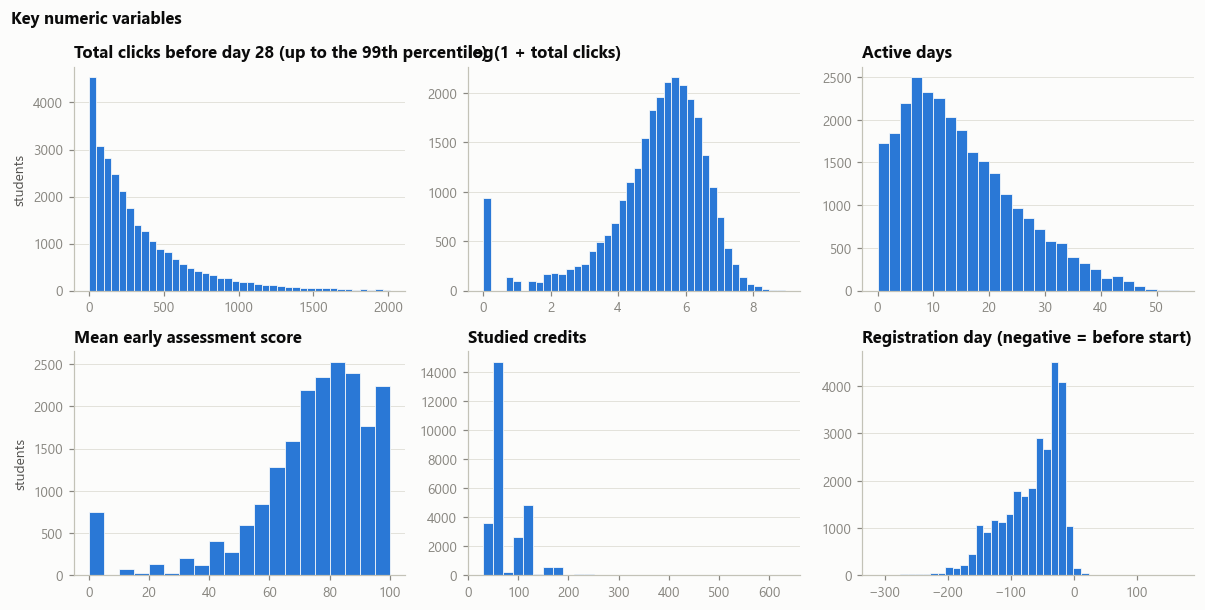

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(11, 5.6))
def hist(ax, s, title, bins=40, color=C_OK, xlabel=None):
    ax.hist(s.dropna(), bins=bins, color=color, edgecolor=SURFACE, linewidth=0.5)
    ax.set_title(title); ax.set_xlabel(xlabel or ""); ax.grid(axis="x", visible=False)
hist(axes[0, 0], master.clicks_total[master.clicks_total <= master.clicks_total.quantile(.99)], "Total clicks before day 28 (up to the 99th percentile)")
hist(axes[0, 1], np.log1p(master.clicks_total), "log(1 + total clicks)")
hist(axes[0, 2], master.active_days, "Active days", bins=range(0, 55, 2))
hist(axes[1, 0], master.mean_score_early, "Mean early assessment score", bins=20)
hist(axes[1, 1], master.studied_credits, "Studied credits", bins=30)
hist(axes[1, 2], master.date_registration, "Registration day (negative = before start)", bins=40)
axes[0, 0].set_ylabel("students"); axes[1, 0].set_ylabel("students")
fig.suptitle("Key numeric variables", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
savefig(fig, "03_univariate_numeric.png"); plt.show()

In [14]:
# A spike of early scores near 0 shows up in the histogram. Is it real low marks or a coding artefact?
sa_raw = pd.read_csv(RAW / "studentAssessment.csv", na_values=["?"])
asm = pd.read_csv(RAW / "assessments.csv", na_values=["?"])
sc = sa_raw.merge(asm, on="id_assessment", validate="many_to_one")
sc["score_is_1"] = sc.score.between(0.5, 1.5)
per = (sc.groupby(["code_module", "code_presentation", "id_assessment", "assessment_type", "date"])
         .agg(submissions=("score", "size"), score_1=("score_is_1", "sum")).reset_index())
per["share_score_1"] = per.score_1 / per.submissions
print("Assessments with the most submissions scored exactly 1:")
print(per.sort_values("score_1", ascending=False).head(3).to_string(index=False))
top_id = int(per.sort_values("score_1", ascending=False).iloc[0].id_assessment)
print(f"\nScore values in assessment {top_id}:")
print(sc.loc[sc.id_assessment == top_id, "score"].round(0).value_counts().head(6).to_string())

# What does a mean early score of 1 mean for risk, compared with genuine low marks?
s_ = master.mean_score_early
groups = pd.cut(s_, [-0.1, 0.5, 1.5, 40, 70, 100.1], labels=["exactly 0", "about 1", "5 to 40", "40 to 70", "70 to 100"])
display(master.groupby(groups, observed=True).target_at_risk.agg(n="size", at_risk_rate="mean"))
print("modules of the 'about 1' group:", master.loc[s_.between(0.5, 1.5), "code_module"].value_counts().to_dict())

Assessments with the most submissions scored exactly 1:
code_module code_presentation  id_assessment assessment_type    date  submissions  score_1  share_score_1
        BBB             2014J          15020             TMA  19.000         1776      717          0.404
        GGG             2014J          37437             TMA 173.000          500        3          0.006
        BBB             2014J          15023             TMA 152.000         1328        1          0.001

Score values in assessment 15020:
score
100.000    1022
1.000       717
0.000        15
80.000        9
75.000        4
90.000        2


,n,at_risk_rate
mean_score_early,,
exactly 0,73,0.849
about 1,671,0.340
5 to 40,785,0.859
40 to 70,5581,0.557
70 to 100,12672,0.294


modules of the 'about 1' group: {'BBB': 671}


**Observed.** The spike near zero in `mean_score_early` is not a set of failing students. Only 73 students have an average of exactly 0, but 671 have an average of exactly 1, almost all in module BBB.
They come from one assessment: BBB 2014J assessment 15020 (a tutor-marked assignment due on day 19). Its scores are only ever **100 (1,022 submissions) or 1 (717 submissions)**, with nearly nothing in between.
It is a completion-style coding, not a graded mark. Students with a mean of about 1 have an at-risk rate of only 34.0%, which is *below* the overall 44.2%, whereas students with a genuine zero (84.9%) or a low mark of 5 to 40 (85.9%) are mostly at risk. A real failing mark would behave like the latter.

**Why it matters.** Averaging this assessment with ordinary marks makes a "1" look like a catastrophic score, which would distort `mean_score_early` for BBB students and could teach a model the wrong lesson about low scores.
**Action.** In notebook 04, rebuild the early score features from the raw submissions: use each submission's percentile rank within its own assessment instead of the raw mark, and treat assessment 15020 as a binary completion indicator. List it as a coding inconsistency in the report.

In [15]:
cat_list = ["code_module", "code_presentation", "gender", "region", "highest_education", "imd_band", "age_band", "disability", "num_of_prev_attempts"]
for c in cat_list:
    t = pd.concat([master[c].value_counts(dropna=False).rename("n"), master[c].value_counts(normalize=True, dropna=False).mul(100).rename("share_%")], axis=1)
    print(f"\n{c}"); print(t.sort_index().to_string(float_format=lambda v: f"{v:,.1f}"))


code_module
                n  share_%
code_module               
AAA           718      2.6
BBB          6435     23.4
CCC          3523     12.8
DDD          5287     19.2
EEE          2553      9.3
FFF          6599     24.0
GGG          2438      8.8

code_presentation
                      n  share_%
code_presentation               
2013B              4131     15.0
2013J              7687     27.9
2014B              6516     23.6
2014J              9219     33.5

gender
            n  share_%
gender                
F       12373     44.9
M       15180     55.1

region
                         n  share_%
region                             
East Anglian Region   2811     10.2
East Midlands Region  1925      7.0
Ireland               1106      4.0
London Region         2576      9.3
North Region          1533      5.6
North Western Region  2338      8.5
Scotland              3162     11.5
South East Region     1770      6.4
South Region          2624      9.5
South West Region     2

In [16]:
print("Target, binary:"); print(master.target_at_risk.value_counts().rename({0: "not at risk", 1: "at risk"}).to_frame("n").assign(share=lambda d: d.n / len(master)).to_string())
print("\nTarget, four outcomes:"); print(master.target_final_result.value_counts().to_frame("n").assign(share=lambda d: d.n / len(master)).to_string())
print("\nAt-risk rate by presentation:"); print(rate_table(master, "code_presentation")[["n", "rate"]].to_string())
print("\nAt-risk rate by module:"); print(rate_table(master, "code_module")[["n", "rate"]].to_string())

Target, binary:
                    n  share
target_at_risk              
not at risk     15385  0.558
at risk         12168  0.442

Target, four outcomes:
                         n  share
target_final_result              
Pass                 12361  0.449
Fail                  7044  0.256
Withdrawn             5124  0.186
Distinction           3024  0.110

At-risk rate by presentation:
                      n  rate
code_presentation            
2013B              4131 0.493
2013J              7687 0.418
2014B              6516 0.485
2014J              9219 0.408

At-risk rate by module:
                n  rate
code_module            
AAA           718 0.260
BBB          6435 0.417
CCC          3523 0.524
DDD          5287 0.506
EEE          2553 0.354
FFF          6599 0.447
GGG          2438 0.379


**Observed (categorical variables).** The sample is fairly balanced on gender (55% male), and every region has between 4% and 11.5% of students. Education is concentrated at A level or below (83%), 70% are under 35, 9.5% declare a disability and 87% have no previous attempt.
Module sizes are very unequal (AAA 2.6% to FFF 24.0%) and so are presentations (15% to 33.5%).

**Target.** The binary target is nearly balanced (44.2% at risk). The four outcomes are Pass 44.9%, Fail 25.6%, Withdrawn 18.6%, Distinction 11.0%, so imbalance appears only in the four-way view and inside single modules.
The at-risk rate differs strongly by module (AAA 26.0% to CCC 52.4%) and by season of start: February "B" presentations are about 7 percentage points higher than October "J" ones (48.5 to 49.3% vs 40.8 to 41.8%).

**Why it matters.** Module and start season are strong context variables; any comparison of students across modules must account for them. Because the pattern repeats the same way in both years, the target rate itself should be stable between 2013 and 2014 (checked below).
**Action.** Keep `code_module` and `start_term` as context features. Report metrics per module and per presentation.

### Target rate by year

In [17]:
print(master.groupby("year").target_at_risk.agg(n="size", at_risk_rate="mean").to_string())
print(master.groupby(["year", "start_term"]).target_at_risk.agg(n="size", at_risk_rate="mean").to_string())

          n  at_risk_rate
year                     
2013  11818         0.444
2014  15735         0.440
                    n  at_risk_rate
year start_term                    
2013 B           4131         0.493
     J           7687         0.418
2014 B           6516         0.485
     J           9219         0.408


**Observed.** The at-risk rate is almost identical in the two years (44.4% in 2013, 44.0% in 2014), and the seasonal gap repeats: February starts 49.3% and 48.5%, October starts 41.8% and 40.8%.
**Why it matters.** The planned split (train on 2013, test on 2014) has the same season mix on both sides and almost the same target rate, so a drop in test performance can be blamed on changes in the data or the student mix, not on a shifting target rate.
**Action.** Keep the temporal split. Check feature drift (module mix, engagement levels) in notebook 07.

## 3. Bivariate exploration

Seven research-driven pairs across four pair types, each tied to a research question (RQ1 association, RQ4 equity).

### Pair 1 (numerical x numerical, RQ1): total clicks vs active days

Spearman rho = 0.885 | Pearson r = 0.769 | Pearson on log1p(clicks) = 0.774


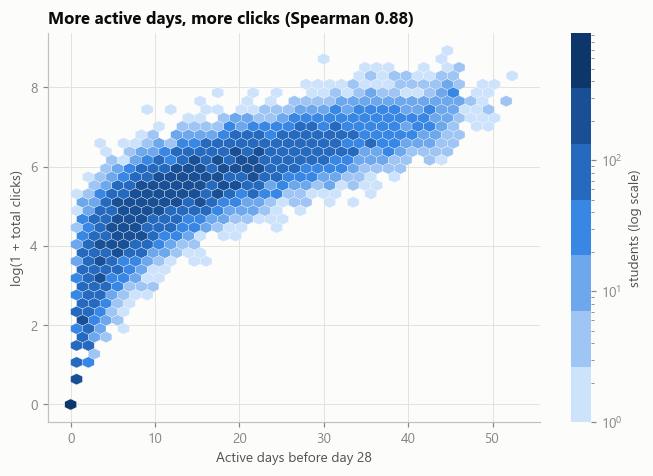

In [18]:
r1 = master.clicks_total.corr(master.active_days, method="spearman")
r1p = master.clicks_total.corr(master.active_days, method="pearson")
print(f"Spearman rho = {r1:.3f} | Pearson r = {r1p:.3f} | Pearson on log1p(clicks) = {np.log1p(master.clicks_total).corr(master.active_days):.3f}")

fig, ax = plt.subplots(figsize=(6.2, 4.4))
h = ax.hexbin(master.active_days, np.log1p(master.clicks_total), gridsize=38, cmap=plt.matplotlib.colors.ListedColormap(SEQ), mincnt=1, bins="log", linewidths=0.2, edgecolors=SURFACE)
cb = fig.colorbar(h, ax=ax); cb.set_label("students (log scale)"); cb.outline.set_visible(False)
ax.set_xlabel("Active days before day 28"); ax.set_ylabel("log(1 + total clicks)")
ax.set_title(f"More active days, more clicks (Spearman {r1:.2f})")
fig.tight_layout(); savefig(fig, "03_pair1_clicks_vs_activedays.png"); plt.show()

**Observed.** Clicks and active days move together very strongly (Spearman 0.885, Pearson 0.77, and 0.77 on the log scale). The plot shows a clean monotone relationship that fans out at high activity.
**Why it matters.** The two are close to redundant, which makes regression coefficients unstable and feature-importance rankings arbitrary.
**Action.** In notebook 04 keep one variable per redundant group (or use PCA or a regularised model), and cluster on a small set of log-scaled, non-redundant engagement features.

### Pair 2 (numerical x numerical, RQ1): total clicks vs early assessment score

n = 19,782 (students with an early submission) | Spearman rho = 0.272 | Pearson r = 0.220
Spearman by module: {'AAA': np.float64(0.37), 'BBB': np.float64(0.116), 'CCC': np.float64(0.314), 'DDD': np.float64(0.281), 'EEE': np.float64(0.099), 'FFF': np.float64(0.264), 'GGG': np.float64(0.217)}
Score ceiling: share of early scores >= 95: 0.113 | share of scores < 40: 0.067


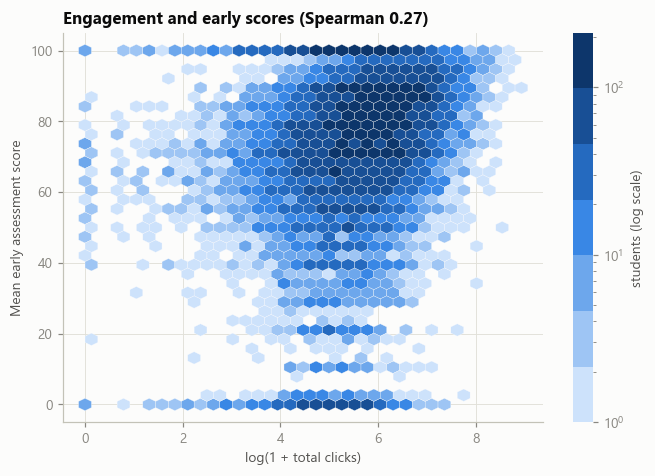

In [19]:
d = master.dropna(subset=["mean_score_early"])
r2 = d.clicks_total.corr(d.mean_score_early, method="spearman")
print(f"n = {len(d):,} (students with an early submission) | Spearman rho = {r2:.3f} | Pearson r = {d.clicks_total.corr(d.mean_score_early):.3f}")
print("Spearman by module:", {m: round(g.clicks_total.corr(g.mean_score_early, method="spearman"), 3) for m, g in d.groupby("code_module")})
print("Score ceiling: share of early scores >= 95:", round((d.mean_score_early >= 95).mean(), 3), "| share of scores < 40:", round((d.mean_score_early < 40).mean(), 3))

fig, ax = plt.subplots(figsize=(6.2, 4.4))
h = ax.hexbin(np.log1p(d.clicks_total), d.mean_score_early, gridsize=34, cmap=plt.matplotlib.colors.ListedColormap(SEQ), mincnt=1, bins="log", linewidths=0.2, edgecolors=SURFACE)
cb = fig.colorbar(h, ax=ax); cb.set_label("students (log scale)"); cb.outline.set_visible(False)
ax.set_xlabel("log(1 + total clicks)"); ax.set_ylabel("Mean early assessment score")
ax.set_title(f"Engagement and early scores (Spearman {r2:.2f})")
fig.tight_layout(); savefig(fig, "03_pair2_clicks_vs_score.png"); plt.show()

**Observed.** Engagement and early marks are only weakly related (Spearman 0.27 overall). By module it ranges from 0.10 (EEE) to 0.37 (AAA). Scores sit near a ceiling (11.3% of early means are at least 95) and there is a spike of students at a score of about 1, which section 2 shows is a coding artefact of one assessment, not a set of failing marks.
**Why it matters.** Time on the platform and marks measure different things, so each can add information. The weak link in some modules also warns against treating clicks as a stand-in for learning.
**Action.** Keep both families of features. Keep a module-aware treatment of scores.

### Pair 3 (binary outcome x numerical, RQ1): which early features separate at-risk students?

AUC here is the probability that a randomly chosen *not at-risk* student has a higher value than a randomly chosen at-risk student (0.5 = no separation).

,auc_not_at_risk_higher,spearman_with_target,n_used,separation
mean_score_early,0.674,-0.296,19782,0.349
active_days,0.665,-0.284,27553,0.331
clicks_homepage,0.661,-0.277,27553,0.322
clicks_total,0.661,-0.277,27553,0.322
clicks_forumng,0.648,-0.255,27553,0.295
clicks_w2,0.647,-0.254,27553,0.295
clicks_w4,0.640,-0.242,27553,0.280
clicks_w1,0.638,-0.238,27553,0.276
clicks_prestart,0.629,-0.223,27553,0.259
n_sites,0.626,-0.217,27553,0.252


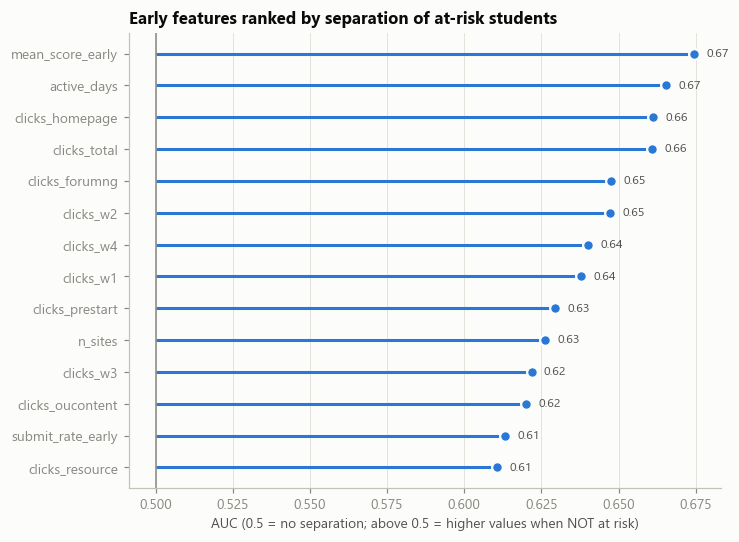

In [20]:
cand = ["clicks_total", "active_days", "n_sites", "clicks_prestart", "clicks_w1", "clicks_w2", "clicks_w3", "clicks_w4", "clicks_forumng", "clicks_oucontent",
        "clicks_homepage", "clicks_quiz", "clicks_subpage", "clicks_resource", "clicks_other", "first_click_day", "n_assess_submitted", "n_due_submitted",
        "submit_rate_early", "mean_score_early", "date_registration", "studied_credits", "num_of_prev_attempts", "edu_level", "imd_order", "age_order"]
cand = [c for c in cand if c in master.columns]
es = pd.DataFrame({
    "auc_not_at_risk_higher": {c: 1 - auc_pos(master[c], master.target_at_risk) for c in cand},
    "spearman_with_target": {c: master[c].corr(master.target_at_risk, method="spearman") for c in cand},
    "n_used": {c: int(master[c].notna().sum()) for c in cand},
})
es["separation"] = (es.auc_not_at_risk_higher - 0.5).abs() * 2
es = es.sort_values("separation", ascending=False)
display(es)
es.to_csv(OUT / "eda_effect_sizes_numeric.csv")

top = es.head(14).iloc[::-1]
fig, ax = plt.subplots(figsize=(6.8, 5))
ax.hlines(top.index, 0.5, top.auc_not_at_risk_higher, color=C_OK, linewidth=2)
ax.plot(top.auc_not_at_risk_higher, top.index, "o", color=C_OK, markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5)
ax.axvline(0.5, color=MUTED, linewidth=1); ax.set_xlabel("AUC (0.5 = no separation; above 0.5 = higher values when NOT at risk)")
ax.set_title("Early features ranked by separation of at-risk students"); ax.grid(axis="y", visible=False)
for v, y in zip(top.auc_not_at_risk_higher, top.index): ax.text(v + 0.004, y, f"{v:.2f}", va="center", fontsize=8, color=INK2)
fig.tight_layout(); savefig(fig, "03_pair3_feature_auc.png"); plt.show()

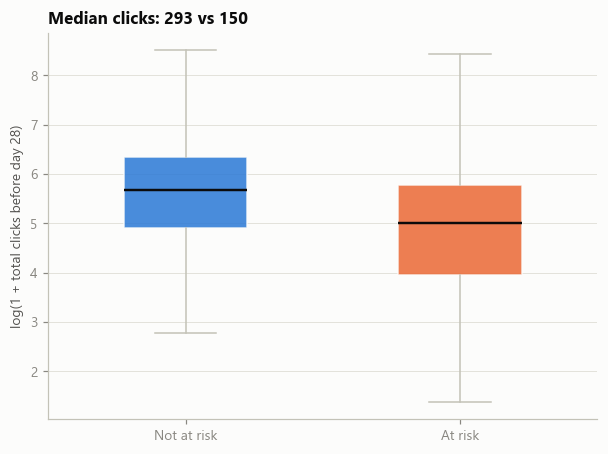

medians (not at risk, at risk): [np.float64(293.0), np.float64(150.0)] | AUC (not-at-risk higher): 0.661


In [21]:
fig, ax = plt.subplots(figsize=(5.6, 4.2))
data = [np.log1p(master.loc[master.target_at_risk == 0, "clicks_total"]), np.log1p(master.loc[master.target_at_risk == 1, "clicks_total"])]
bp = ax.boxplot(data, widths=0.45, patch_artist=True, showfliers=False, medianprops=dict(color=INK, linewidth=1.6), whiskerprops=dict(color=AXIS), capprops=dict(color=AXIS))
for patch, col in zip(bp["boxes"], [C_OK, C_RISK]):
    patch.set(facecolor=col, alpha=0.85, edgecolor=SURFACE)
ax.set_xticks([1, 2], ["Not at risk", "At risk"]); ax.set_ylabel("log(1 + total clicks before day 28)"); ax.grid(axis="x", visible=False)
med = [master.loc[master.target_at_risk == k, "clicks_total"].median() for k in (0, 1)]
ax.set_title(f"Median clicks: {med[0]:.0f} vs {med[1]:.0f}")
fig.tight_layout(); savefig(fig, "03_pair3_clicks_by_outcome.png"); plt.show()
print("medians (not at risk, at risk):", med, "| AUC (not-at-risk higher):", round(1 - auc_pos(master.clicks_total, master.target_at_risk), 3))

**Observed.** No single early feature separates the groups strongly. The best are `mean_score_early` (AUC 0.67), `active_days` (0.665) and `clicks_total` (0.66). The median student not at risk made 293 clicks vs 150 for an at-risk student. Registration timing carries no signal (AUC 0.50), and a later first click is slightly more common among at-risk students (AUC 0.445, i.e. higher values when at risk).
**Why it matters.** This sets an honest expectation: simple rules reach an AUC of about 0.66 to 0.67, so a day-28 model will be useful but modest, not near-perfect.
**Action.** Do not promise high accuracy. In notebook 07 judge models on ranking quality (AUC, precision at the top k) and on per-group errors, not accuracy.

### Pair 4 (categorical x numerical, RQ1): module vs total clicks

Kruskal-Wallis H = 7,129, epsilon-squared = 0.259 (0.01 small, 0.06 medium, 0.14 large)


,count,25%,50%,75%,max
code_module,,,,,
AAA,718.000,184.000,373.500,665.000,"4,181.000"
BBB,"6,435.000",47.000,118.000,227.500,"4,593.000"
CCC,"3,523.000",126.000,238.000,426.500,"5,740.000"
DDD,"5,287.000",110.000,225.000,411.000,"4,025.000"
EEE,"2,553.000",188.000,327.000,520.000,"3,793.000"
FFF,"6,599.000",237.000,474.000,814.000,"7,570.000"
GGG,"2,438.000",14.000,48.000,108.000,"1,831.000"


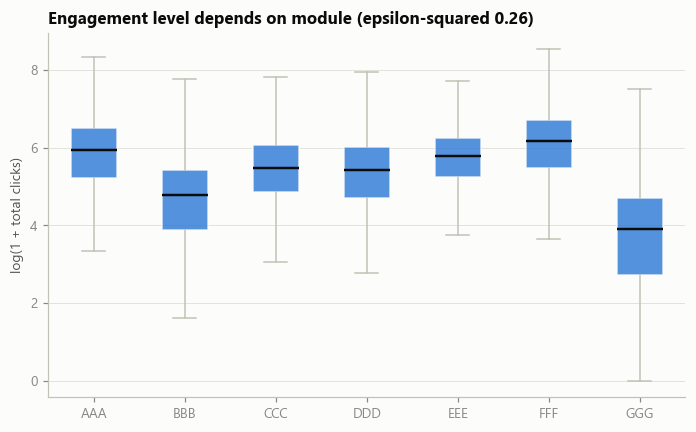

In [22]:
groups = [g.clicks_total.values for _, g in master.groupby("code_module")]
H, p = stats.kruskal(*groups)
eps2 = H / (len(master) - 1)
print(f"Kruskal-Wallis H = {H:,.0f}, epsilon-squared = {eps2:.3f} (0.01 small, 0.06 medium, 0.14 large)")
display(master.groupby("code_module").clicks_total.describe()[["count", "25%", "50%", "75%", "max"]])

order = sorted(master.code_module.unique())
fig, ax = plt.subplots(figsize=(6.4, 4))
bp = ax.boxplot([np.log1p(master.loc[master.code_module == m, "clicks_total"]) for m in order], widths=0.5, patch_artist=True, showfliers=False,
                medianprops=dict(color=INK, linewidth=1.6), whiskerprops=dict(color=AXIS), capprops=dict(color=AXIS))
for patch in bp["boxes"]: patch.set(facecolor=C_OK, alpha=0.8, edgecolor=SURFACE)
ax.set_xticks(range(1, len(order) + 1), order); ax.set_ylabel("log(1 + total clicks)"); ax.grid(axis="x", visible=False)
ax.set_title(f"Engagement level depends on module (epsilon-squared {eps2:.2f})")
fig.tight_layout(); savefig(fig, "03_pair4_clicks_by_module.png"); plt.show()

**Observed.** Module differences in engagement are large (Kruskal-Wallis epsilon-squared 0.26, a large effect): the median student in module FFF made 474 clicks, in GGG only 48. This matters for the earlier result: **inside each module the engagement signal is stronger than in the pooled data** (table in the subgroup checks below: AUC from 0.64 to 0.74 vs 0.661 pooled; EEE 0.74, FFF 0.72, CCC 0.70, DDD 0.70, BBB 0.67, AAA 0.64, GGG 0.64).
**Why it matters.** Module differences in activity partly hide the within-module signal, and a raw click threshold would label most of GGG as low engagement.
**Action.** Build within-module relative engagement features in notebook 04 (for example z-score or percentile of log clicks inside each module-presentation) and keep the module as context.

### Pair 5 (categorical x categorical, RQ4): deprivation band (IMD) vs at-risk

chi2 = 414.6, dof = 9, Cramer's V = 0.124 | min expected cell count = 1,002
Spearman(imd_order, at_risk) = -0.122


,n,at_risk,rate,lo,hi
imd_band,,,,,
0-10,2651,1487,0.561,0.542,0.580
10-20,2828,1470,0.520,0.501,0.538
20-30,2988,1499,0.502,0.484,0.520
30-40,3000,1340,0.447,0.429,0.465
40-50,2715,1198,0.441,0.423,0.460
50-60,2690,1166,0.433,0.415,0.452
60-70,2512,1004,0.400,0.381,0.419
70-80,2520,1037,0.412,0.392,0.431
80-90,2380,887,0.373,0.353,0.392


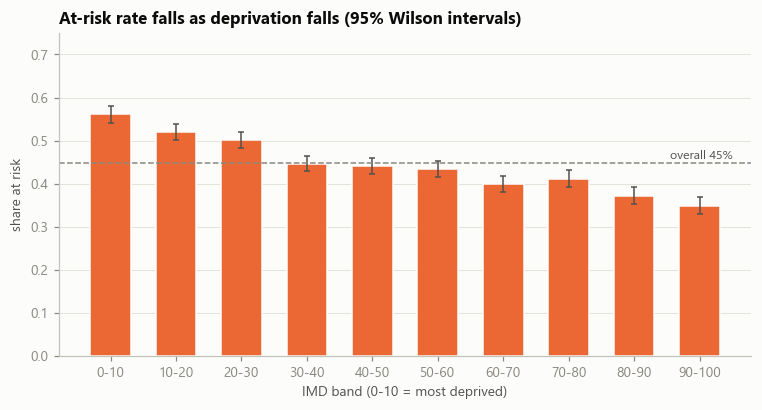

In [23]:
IMD_ORDER = ["0-10", "10-20", "20-30", "30-40", "40-50", "50-60", "60-70", "70-80", "80-90", "90-100"]
d = master.dropna(subset=["imd_band"])
ct = pd.crosstab(d.imd_band, d.target_at_risk).reindex(IMD_ORDER)
chi2, p, dof, exp = stats.chi2_contingency(ct, correction=False)
print(f"chi2 = {chi2:,.1f}, dof = {dof}, Cramer's V = {cramers_v(ct):.3f} | min expected cell count = {exp.min():,.0f}")
print(f"Spearman(imd_order, at_risk) = {d.imd_order.corr(d.target_at_risk, method='spearman'):.3f}")
rt = rate_table(d, "imd_band", IMD_ORDER)
display(rt)

fig, ax = plt.subplots(figsize=(7, 3.8))
x = np.arange(len(rt))
ax.bar(x, rt.rate, width=0.62, color=C_RISK, edgecolor=SURFACE)
ax.errorbar(x, rt.rate, yerr=[rt.rate - rt.lo, rt.hi - rt.rate], fmt="none", ecolor=INK2, elinewidth=1, capsize=2)
overall = d.target_at_risk.mean(); ax.axhline(overall, color=MUTED, linestyle="--", linewidth=1)
ax.text(len(rt) - 0.5, overall + 0.01, f"overall {overall:.0%}", ha="right", color=INK2, fontsize=8)
ax.set_xticks(x, rt.index); ax.set_xlabel("IMD band (0-10 = most deprived)"); ax.set_ylabel("share at risk"); ax.set_ylim(0, 0.75); ax.grid(axis="x", visible=False)
ax.set_title("At-risk rate falls as deprivation falls (95% Wilson intervals)")
fig.tight_layout(); savefig(fig, "03_pair5_imd_vs_risk.png"); plt.show()

**Observed.** The at-risk rate falls steadily with lower deprivation: 56.1% in the most deprived band to 34.9% in the least deprived, a 21 point gap (Cramer's V 0.124, Spearman -0.12). All expected cell counts exceed 1,000, so sparse cells are not a concern.
**Does it survive controls?** Yes (logistic models in the subgroup checks below). The odds ratio per IMD band step is 0.916 on its own, 0.912 after adjusting for module and presentation, 0.925 after adding background variables, and 0.927 after adding early engagement. Each step toward less deprivation lowers the odds of being at risk by about 7 to 9%, and early clicks explain almost none of it.
**Why it matters.** This is the central equity result (RQ4). A model that never sees IMD will still carry it indirectly, and IMD-related error differences must be measured. These are associations, not causes.
**Action.** Keep IMD available for group-wise evaluation and compare models with and without it.

### Pair 6 (categorical x categorical, RQ4): other background variables vs at-risk

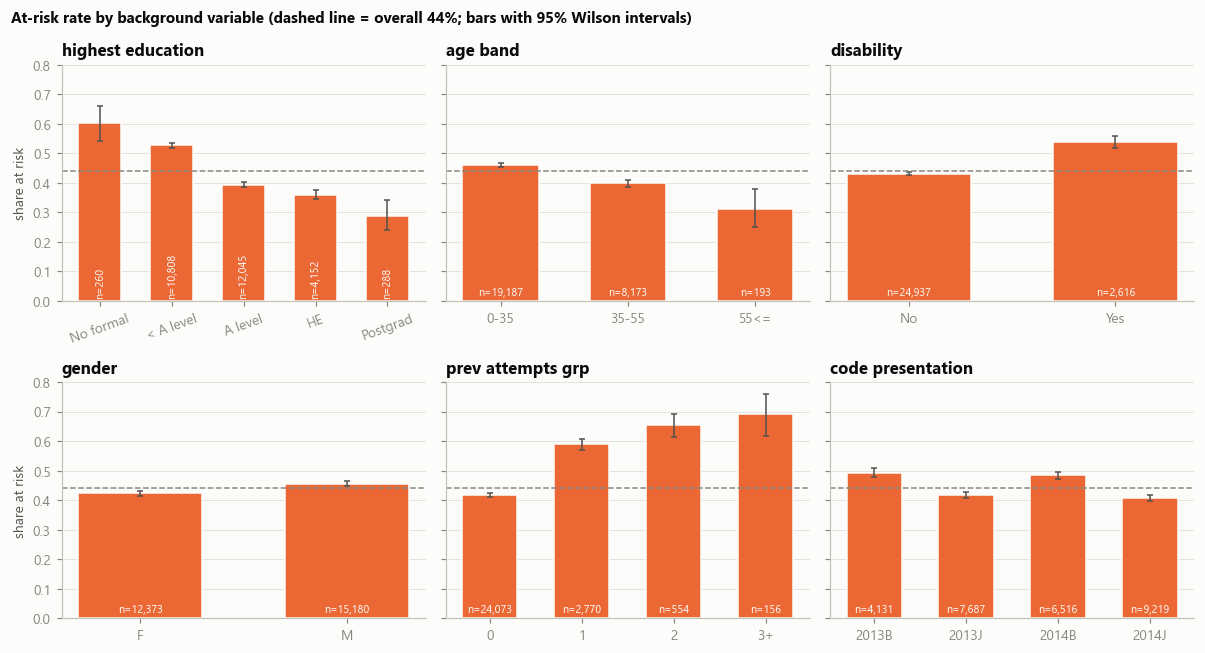

odds ratio at risk, disability=Y vs other: 1.54 (95% CI 1.42 to 1.67)
odds ratio at risk, gender=M vs other: 1.14 (95% CI 1.09 to 1.20)


,cramers_v,rate_min,rate_max,min_group_n
variable,,,,
highest_education,0.147,0.288,0.604,260
age_band,0.062,0.311,0.462,193
disability,0.063,0.431,0.539,2616
gender,0.032,0.424,0.456,12373
prev_attempts_grp,0.125,0.418,0.692,156
code_presentation,0.074,0.408,0.493,4131


In [24]:
d = master.copy()
d["prev_attempts_grp"] = d.num_of_prev_attempts.clip(upper=3).astype(str).replace({"3": "3+"})
panels = [("highest_education", ["No Formal quals", "Lower Than A Level", "A Level or Equivalent", "HE Qualification", "Post Graduate Qualification"],
           ["No formal", "< A level", "A level", "HE", "Postgrad"]),
          ("age_band", ["0-35", "35-55", "55<="], None), ("disability", ["N", "Y"], ["No", "Yes"]),
          ("gender", ["F", "M"], None), ("prev_attempts_grp", ["0", "1", "2", "3+"], None), ("code_presentation", ["2013B", "2013J", "2014B", "2014J"], None)]
eff_rows = []
fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharey=True)
overall = d.target_at_risk.mean()
for ax, (col, order, labels) in zip(axes.ravel(), panels):
    rt = rate_table(d, col, order); x = np.arange(len(rt))
    ax.bar(x, rt.rate, width=0.6, color=C_RISK, edgecolor=SURFACE)
    ax.errorbar(x, rt.rate, yerr=[rt.rate - rt.lo, rt.hi - rt.rate], fmt="none", ecolor=INK2, elinewidth=1, capsize=2)
    ax.axhline(overall, color=MUTED, linestyle="--", linewidth=1)
    ax.set_xticks(x, labels or order, rotation=0 if len(order) < 5 else 20); ax.set_title(col.replace("_", " ")); ax.set_ylim(0, 0.8); ax.grid(axis="x", visible=False)
    for xi, (v, n_) in enumerate(zip(rt.rate, rt.n)): ax.text(xi, 0.02, f"n={n_:,}", ha="center", fontsize=7, color=SURFACE if v > 0.1 else INK2, rotation=90 if len(order) > 4 else 0)
    ct = pd.crosstab(d[col], d.target_at_risk).reindex(order)
    eff_rows.append(dict(variable=col, cramers_v=cramers_v(ct), rate_min=rt.rate.min(), rate_max=rt.rate.max(), min_group_n=int(rt.n.min())))
axes[0, 0].set_ylabel("share at risk"); axes[1, 0].set_ylabel("share at risk")
fig.suptitle(f"At-risk rate by background variable (dashed line = overall {overall:.0%}; bars with 95% Wilson intervals)", x=0.01, ha="left", fontweight="bold", fontsize=10)
fig.tight_layout(); savefig(fig, "03_pair6_background_vs_risk.png"); plt.show()

eff = pd.DataFrame(eff_rows).set_index("variable")
# odds ratios for the two binary variables
for col, pos in (("disability", "Y"), ("gender", "M")):
    a = ((d[col] == pos) & (d.target_at_risk == 1)).sum(); b = ((d[col] == pos) & (d.target_at_risk == 0)).sum()
    c = ((d[col] != pos) & (d.target_at_risk == 1)).sum(); e = ((d[col] != pos) & (d.target_at_risk == 0)).sum()
    o, lo, hi = odds_ratio(a, b, c, e); print(f"odds ratio at risk, {col}={pos} vs other: {o:.2f} (95% CI {lo:.2f} to {hi:.2f})")
eff

**Observed.** Highest education has the largest background effect (Cramer's V 0.147): 60.4% of students with no formal qualification are at risk (n=260) vs 28.8% of postgraduates (n=288). Previous attempts are next (V 0.125): 41.8% with none vs 69.2% with three or more (n=156). Disability: 53.9% vs 43.1% (odds ratio 1.54, 95% CI 1.42 to 1.67; 1.37 after adjustment).
Age: 46.2% for under-35s vs 31.1% for 55 and over (only 193 students). Gender: men 45.6% vs women 42.4% (odds ratio 1.14), but after adjustment the gender odds ratio is 1.005, so the raw gap comes from module mix and other variables.

**Why it matters.** The small groups have wide intervals, so their exact rates should not be over-read; the gender result shows how a raw comparison can mislead when module composition differs.
**Action.** Report intervals with every rate. Use ordinal codes in models. Use adjusted comparisons before saying any group differs.

### Pair 7 (time x variable, RQ1): daily click profile by outcome

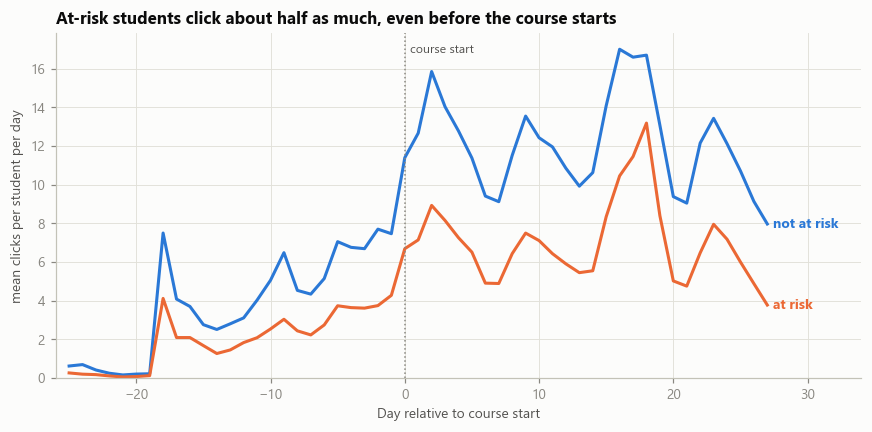

target_at_risk  not_at_risk_clicks_per_student  at_risk_clicks_per_student  ratio_at_risk_to_not
week                                                                                            
pre-start                               94.408                      49.798                 0.527
w1                                      87.485                      49.595                 0.567
w2                                      79.324                      43.732                 0.551
w3                                      97.430                      62.397                 0.640
w4                                      74.555                      41.036                 0.550


In [25]:
tg = master[KEY + ["target_at_risk"]]
ev = sv.merge(tg, on=KEY, how="inner")
n_by = master.target_at_risk.value_counts()
daily = ev.groupby(["date", "target_at_risk"]).sum_click.sum().unstack(fill_value=0)
daily = daily.div(n_by.reindex(daily.columns), axis=1).reindex(range(-25, CUTOFF_DAY), fill_value=0)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(daily.index, daily[0], color=C_OK, linewidth=2); ax.plot(daily.index, daily[1], color=C_RISK, linewidth=2)
ax.axvline(0, color=MUTED, linewidth=1, linestyle=":"); ax.text(0.4, ax.get_ylim()[1] * 0.97, "course start", color=INK2, fontsize=8, va="top")
ax.text(daily.index[-1] + 0.4, daily[0].iloc[-1], "not at risk", color=C_OK, va="center", fontsize=9, fontweight="bold")
ax.text(daily.index[-1] + 0.4, daily[1].iloc[-1], "at risk", color=C_RISK, va="center", fontsize=9, fontweight="bold")
ax.set_xlim(-26, CUTOFF_DAY + 6); ax.set_xlabel("Day relative to course start"); ax.set_ylabel("mean clicks per student per day")
ax.set_ylim(0, None); ax.set_title("At-risk students click about half as much, even before the course starts")
fig.tight_layout(); savefig(fig, "03_pair7_daily_profile.png"); plt.show()

wk = daily.copy(); wk["week"] = np.where(wk.index < 0, "pre-start", "w" + ((wk.index // 7) + 1).astype(str))
print((wk.groupby("week")[[0, 1]].sum().assign(ratio_at_risk_to_not=lambda t: t[1] / t[0])).rename(columns={0: "not_at_risk_clicks_per_student", 1: "at_risk_clicks_per_student"}).to_string())

**Observed.** At-risk students click about half as much as others **already before the course starts** (53% as many clicks per student in the pre-start period) and the ratio then stays between 55% and 64% in each of the first four weeks. Both groups share the same rhythm, including a sharp rise about 18 days before the start and repeating peaks later (probably tied to the course calendar, which the data cannot confirm).
**Why it matters.** The engagement gap exists before any course content is experienced, so it reflects student habits and circumstances rather than a reaction to the first weeks. It also means useful signal is available earlier than day 28.
**Action.** Run a cutoff sensitivity analysis (day 0, 14, 28) in notebook 07 to see how much accuracy is gained by waiting.

### Do the patterns survive subgroup and confounding checks?

**(a) Engagement signal within each module** (could the overall pattern be driven by module differences?)

In [26]:
rows = []
for mod, g in master.groupby("code_module"):
    rows.append(dict(module=mod, n=len(g), at_risk_rate=g.target_at_risk.mean(), auc_clicks=1 - auc_pos(g.clicks_total, g.target_at_risk),
                     auc_active_days=1 - auc_pos(g.active_days, g.target_at_risk)))
within = pd.DataFrame(rows).set_index("module")
display(within)
print("pooled AUC clicks_total:", round(1 - auc_pos(master.clicks_total, master.target_at_risk), 3))

,n,at_risk_rate,auc_clicks,auc_active_days
module,,,,
AAA,718,0.260,0.644,0.656
BBB,6435,0.417,0.673,0.670
CCC,3523,0.524,0.701,0.698
DDD,5287,0.506,0.700,0.706
EEE,2553,0.354,0.742,0.751
FFF,6599,0.447,0.720,0.716
GGG,2438,0.379,0.640,0.644


pooled AUC clicks_total: 0.661


**(b) Does the deprivation gradient survive controls?** Logistic regression, odds ratio per one IMD band step (a higher band = less deprived), n = students with a recorded IMD.

In [27]:
d = master.dropna(subset=["imd_order"]).copy()
d["log_clicks"] = np.log1p(d.clicks_total)
d["disab"] = (d.disability == "Y").astype(int)
d["male"] = (d.gender == "M").astype(int)
models = {
    "A: IMD only": "target_at_risk ~ imd_order",
    "B: + module and presentation": "target_at_risk ~ imd_order + C(code_module) + C(code_presentation)",
    "C: + background": "target_at_risk ~ imd_order + C(code_module) + C(code_presentation) + edu_level + age_order + disab + male + num_of_prev_attempts + studied_credits",
    "D: + early engagement": "target_at_risk ~ imd_order + C(code_module) + C(code_presentation) + edu_level + age_order + disab + male + num_of_prev_attempts + studied_credits + log_clicks + active_days",
}
rows = []; fits = {}
for name, f in models.items():
    fit = smf.logit(f, data=d).fit(disp=0); fits[name] = fit
    b, ci = fit.params["imd_order"], fit.conf_int().loc["imd_order"]
    rows.append(dict(model=name, n=int(fit.nobs), or_per_imd_step=np.exp(b), ci_low=np.exp(ci[0]), ci_high=np.exp(ci[1]), pseudo_r2=fit.prsquared))
imd_models = pd.DataFrame(rows).set_index("model")
display(imd_models)

,n,or_per_imd_step,ci_low,ci_high,pseudo_r2
model,,,,,
A: IMD only,26524,0.916,0.908,0.924,0.011
B: + module and presentation,26524,0.912,0.904,0.920,0.027
C: + background,26524,0.925,0.917,0.933,0.053
D: + early engagement,26524,0.927,0.918,0.936,0.141


In [28]:
fit = fits["D: + early engagement"]
tab = pd.DataFrame({"odds_ratio": np.exp(fit.params), "ci_low": np.exp(fit.conf_int()[0]), "ci_high": np.exp(fit.conf_int()[1])})
keep = [i for i in tab.index if not i.startswith("C(") and i != "Intercept"]
print("Model D (adjusted odds ratios, continuous terms per one unit; clicks on the log scale):")
tab.loc[keep]

Model D (adjusted odds ratios, continuous terms per one unit; clicks on the log scale):


,odds_ratio,ci_low,ci_high
imd_order,0.927,0.918,0.936
edu_level,0.651,0.626,0.677
age_order,1.064,1.003,1.128
disab,1.368,1.249,1.497
male,1.005,0.939,1.075
num_of_prev_attempts,1.266,1.191,1.345
studied_credits,1.003,1.002,1.003
log_clicks,0.728,0.705,0.752
active_days,0.953,0.949,0.958


**Observed (model D).** After adjusting for module, presentation, background and early engagement, the odds of being at risk are lower with higher education (odds ratio 0.65 per level), lower with more early engagement (0.73 per unit of log clicks; 0.95 per extra active day) and higher with previous attempts (1.27 per attempt) and declared disability (1.37). Gender is null (1.005). The model explains 14% of the variation (pseudo R-squared 0.141), up from 1% for IMD alone.
**Why it matters.** Several background factors keep their effect after controlling for engagement, so engagement does not explain them away. The modest explained variation again suggests a limited prediction ceiling at day 28.
**Action.** Treat these as adjusted associations to guide feature selection, not as causal effects.

## 4. Four-outcome view by early engagement

In [29]:
q = pd.qcut(master.clicks_total.rank(method="first"), 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
ct4 = pd.crosstab(q, master.target_final_result, normalize="index").mul(100)[["Distinction", "Pass", "Fail", "Withdrawn"]]
ct4.round(1)

target_final_result,Distinction,Pass,Fail,Withdrawn
clicks_total,,,,
Q1 (lowest),5.600,32.000,40.800,21.700
Q2,8.200,43.400,27.600,20.800
Q3,11.400,50.000,20.500,18.200
Q4 (highest),18.800,54.100,13.400,13.700


**Observed.** Low early engagement is associated most strongly with failing, less with withdrawing: from the lowest to the highest engagement quartile, Fail falls from 40.8% to 13.4% (three-fold), while Withdrawn falls only from 21.7% to 13.7%. Distinction rises from 5.6% to 18.8%.
**Why it matters.** "At risk" merges two different mechanisms (struggling vs leaving), and engagement describes the first much better than the second.
**Action.** In notebook 07 report one binary model for the stated target and also separate Fail and Withdrawn models.

## 5. Synthesis for the report

**Three most important characteristics of this dataset**

1. It is observational platform data for 7 modules with strongly different activity levels, so module context must be handled explicitly.
2. Early engagement, assessment behaviour and background all relate to risk, but each only moderately (best single feature AUC 0.67).
3. It contains real equity signals (deprivation, education, disability) that persist after adjustment.

**Greatest threat to validity.** The day-28 population definition (the coding problem in one BBB assessment is second, and fixable). About 5,000 students who left earlier are excluded by design, and 93 Withdrawn students have unknown exit dates; results must be quoted for the day-28 population only.

**What the data can answer.** *Well:* RQ1 (association of early behaviour and background with risk) and RQ4 (group differences). *Partly:* RQ2 (profiles; needs the clustering step) and RQ3 (cohort stability; only four presentations, 2013 vs 2014). *Not at all:* causal questions about why students struggle or whether interventions work.

**Decisions carried into notebook 04**

| Topic | Decision |
|---|---|
| Transforms | `log1p` for click counts; cap `studied_credits` at 360 and `num_of_prev_attempts` at 3 |
| Context | within-module relative engagement (z-score or percentile of log clicks per module-presentation) |
| Scores | rebuild early scores from raw submissions as percentile rank within each assessment; treat BBB 2014J assessment 15020 (coded 1 or 100) as a completion flag |
| Missing | `has_early_score` indicator; imputation inside pipelines after the split |
| Redundancy | one of `clicks_total` / `active_days` per group, or PCA; drop near-constant flags |
| Split | train 2013, test 2014; grouped CV by `id_student` |
| Fairness | keep sensitive attributes for group-wise evaluation; compare with and without |

**Recommendation (decision point): proceed with the dataset**, with the precautions above.

## 6. Save outputs

In [30]:
eff.to_csv(OUT / "eda_effect_sizes_categorical.csv")
imd_models.to_csv(OUT / "eda_imd_logit_models.csv")
within.to_csv(OUT / "eda_within_module_auc.csv")
rules_df.to_csv(OUT / "eda_domain_rule_checks.csv", index=False)
print("saved EDA tables to", OUT.resolve())

saved EDA tables to D:\OneDrive\Study\OneDrive - Cambodia Academy of Digital Technology\MASTER\Term 4\Advanced Data Science\OULAD_Project\outputs
